# 개인 신용평가 스코어카드: 모델보다 '승인 기준점'을 설계하기

**질문**: 대출 신청자 15만 명의 데이터로 부도 위험을 점수화하고, **몇 점 이상을 승인해야 회사 손익이 가장 좋은가?**

| 구분 | 내용 |
|---|---|
| 데이터 | [Give Me Some Credit (Kaggle 2011)](https://www.kaggle.com/c/GiveMeSomeCredit), 150,000명, 2년 내 90일+ 연체 여부 · 출처 상세: `docs/DATA_SOURCES.md` |
| 모델 | ① WoE 로지스틱 스코어카드 (설명 가능, 금융권 표준) ② LightGBM (성능 비교용) |
| 평가 | AUC · Gini · KS · PSI |
| 의사결정 | 승인 기준점별 승인율 / 부도율 / 손익, 승인율 80% 시나리오 |

> 방법론 참고: Siddiqi, N. (2017). *Intelligent Credit Scoring* (2nd ed.). Wiley.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
import scorecard as sc

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
(ROOT / "models").mkdir(exist_ok=True); (ROOT / "reports").mkdir(exist_ok=True)

## 1. 데이터 확인

In [2]:
df = sc.load_gmsc(ROOT / "data/processed/gmsc_train.csv")
print(f"{len(df):,}명 · 부도율 {df.target.mean():.2%}")
summary = pd.DataFrame({
    "설명": [sc.LABELS_KO[f] for f in sc.FEATURES],
    "결측률": df[sc.FEATURES].isna().mean().values,
    "중앙값": df[sc.FEATURES].median().values,
    "99%분위": df[sc.FEATURES].quantile(0.99).values,
    "최댓값": df[sc.FEATURES].max().values,
}, index=sc.FEATURES)
summary

149,999명 · 부도율 6.68%


,설명,결측률,중앙값,99%분위,최댓값
rev_util,리볼빙 한도 사용률,0.0000,0.1542,1.0930,"50,708.0000"
age,나이,0.0000,52.0000,87.0000,109.0000
late_30_59,30~59일 연체 횟수(2년),0.0000,0.0000,4.0000,98.0000
debt_ratio,DTI(월 부채상환액 / 월소득),0.0000,0.3665,"4,979.0800","329,664.0000"
monthly_income,월소득(USD),0.1982,"5,400.0000","25,000.0000","3,008,750.0000"
open_credit_lines,보유 대출·카드 수,0.0000,8.0000,24.0000,58.0000
late_90,90일 이상 연체 횟수,0.0000,0.0000,3.0000,98.0000
real_estate_loans,부동산 담보대출 수,0.0000,1.0000,4.0000,54.0000
late_60_89,60~89일 연체 횟수(2년),0.0000,0.0000,2.0000,98.0000
dependents,부양가족 수,0.0262,0.0000,4.0000,20.0000


**데이터 이슈와 처리 방침**
- `MonthlyIncome` 결측 약 20% → 평균 등으로 채우지 않고 결측 자체를 하나의 구간으로 둔다. 결측이 위험 신호인지는 데이터가 판단하게 한다. 실제로 결측자의 부도율이 더 **낮았다**(아래). 평균 대체를 했다면 이 정보가 사라졌을 것이다.
- 연체 횟수 96·98 → 실제 횟수가 아닌 특수코드라서 `special` 구간으로 분리한다.
- `rev_util`, `debt_ratio`의 극단값 → 구간화(binning)를 하면 이상치 영향이 자동으로 차단된다. 별도로 잘라내지 않는다.

In [3]:
print("특수코드(96/98) 보유자 부도율:", f"{df.loc[df.late_90.isin([96,98]), 'target'].mean():.1%}")
print("소득 결측자 부도율:", f"{df.loc[df.monthly_income.isna(), 'target'].mean():.1%}",
      "| 소득 기재자:", f"{df.loc[df.monthly_income.notna(), 'target'].mean():.1%}")

특수코드(96/98) 보유자 부도율: 54.6%
소득 결측자 부도율: 5.6% | 소득 기재자: 6.9%


## 2. 학습/검증/테스트 분할 (60/20/20, 부도율 층화)

In [4]:
tr, te = train_test_split(df, test_size=0.2, stratify=df.target, random_state=42)
tr, va = train_test_split(tr, test_size=0.25, stratify=tr.target, random_state=42)
print({k: f"{len(d):,}명 / 부도율 {d.target.mean():.2%}" for k, d in [("train", tr), ("valid", va), ("test", te)]})

{'train': '89,999명 / 부도율 6.68%', 'valid': '30,000명 / 부도율 6.68%', 'test': '30,000명 / 부도율 6.68%'}


## 3. 구간화와 WoE · IV
의사결정나무로 부도율이 크게 갈리는 지점을 찾아 변수마다 최대 6개 구간으로 나눈다.
- **WoE** = ln(정상 비율 / 부도 비율): 값이 클수록 안전한 구간
- **IV**: 변수의 예측력. 0.02 미만은 무의미하고, 0.1~0.3은 중간, 0.3 이상은 강함

In [5]:
bins = sc.fit_binnings(tr, tr.target)
iv = (pd.DataFrame({"변수": [sc.LABELS_KO[f] for f in bins], "IV": [b.iv for b in bins.values()],
                    "구간 수": [len(b.stats) for b in bins.values()]}, index=list(bins))
      .sort_values("IV", ascending=False))
iv["예측력"] = pd.cut(iv.IV, [0, .02, .1, .3, 99], labels=["무의미", "약함", "중간", "강함"])
iv

,변수,IV,구간 수,예측력
rev_util,리볼빙 한도 사용률,1.1255,6,강함
late_90,90일 이상 연체 횟수,0.8318,3,강함
late_30_59,30~59일 연체 횟수(2년),0.7388,5,강함
late_60_89,60~89일 연체 횟수(2년),0.5543,3,강함
age,나이,0.2454,6,중간
open_credit_lines,보유 대출·카드 수,0.0969,6,약함
monthly_income,월소득(USD),0.0949,7,약함
debt_ratio,DTI(월 부채상환액 / 월소득),0.0866,6,약함
real_estate_loans,부동산 담보대출 수,0.0664,5,약함
dependents,부양가족 수,0.0369,6,약함


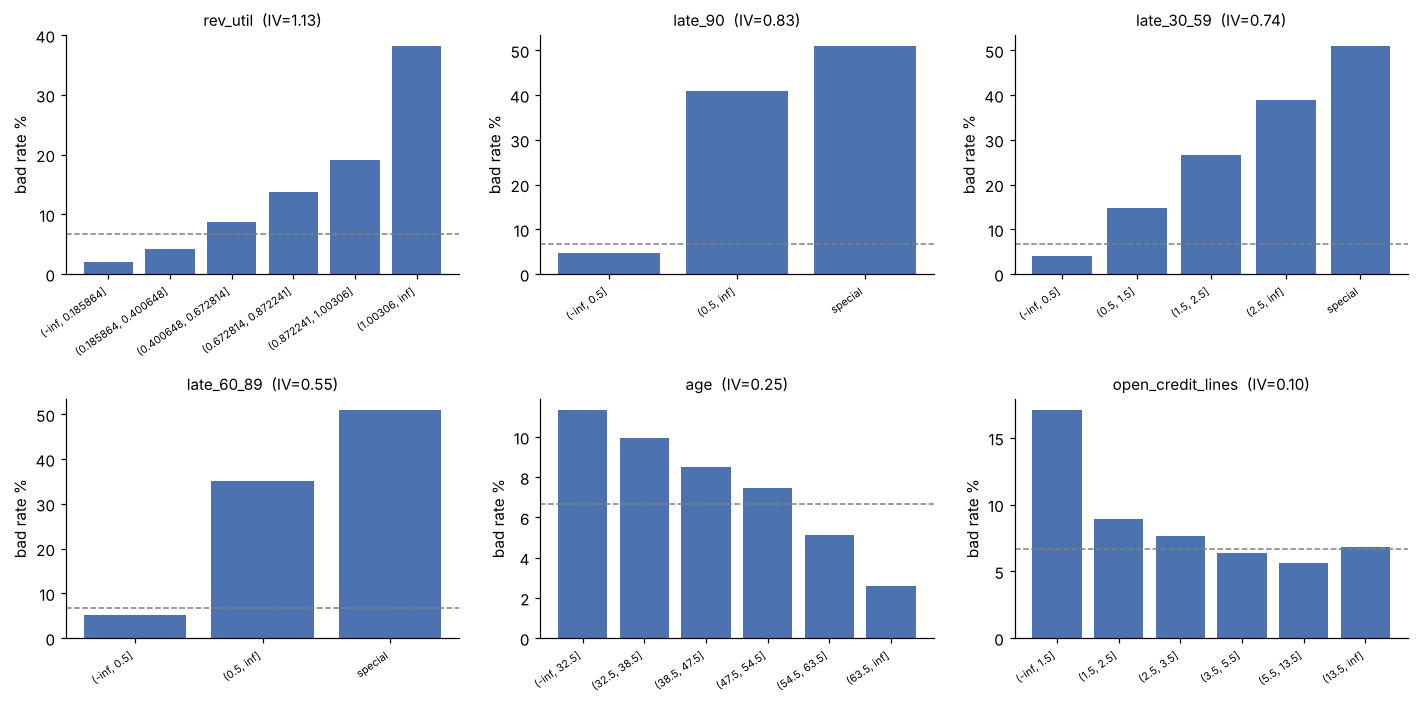

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, f in zip(axes.flat, iv.index[:6]):
    s = pd.DataFrame(bins[f].stats)
    ax.bar(range(len(s)), s.bad_rate * 100, color="#4C72B0")
    ax.set_xticks(range(len(s)), s.bin, rotation=35, ha="right", fontsize=7)
    ax.set_title(f"{f}  (IV={bins[f].iv:.2f})", fontsize=10); ax.set_ylabel("bad rate %")
    ax.axhline(tr.target.mean() * 100, ls="--", c="gray", lw=1)
plt.tight_layout(); plt.savefig(ROOT / "reports/bad_rate_by_bin.png", bbox_inches="tight"); plt.show()

리볼빙 사용률과 연체 이력이 압도적인 변수다. 사용률이 높을수록, 연체가 있을수록 부도율이 급격히 오른다.
나이는 젊을수록 위험하다. 점선은 전체 평균 부도율이다.

## 4. 로지스틱 스코어카드
WoE로 변환한 값으로 로지스틱 회귀를 학습한다. **계수 부호가 직관과 반대인 변수는 제거한다.**
다중공선성 때문에 부호가 뒤집히면 점수표를 설명할 수 없기 때문이고, 이는 실무 검증 기준이기도 하다.

In [7]:
feats = [f for f in iv.index if bins[f].iv >= 0.02]
while True:
    lr = LogisticRegression(C=1.0, max_iter=1000).fit(sc.woe_frame(tr, bins, feats), tr.target)
    wrong = [f for f, c in zip(feats, lr.coef_[0]) if c > 0]   # WoE↑(안전) → logit(부도)↓ 이어야 함
    if not wrong: break
    print("부호 역전으로 제거:", wrong); feats = [f for f in feats if f not in wrong]
print("최종 변수:", feats)
pd.Series(lr.coef_[0], index=feats, name="coef").round(3).to_frame().T

부호 역전으로 제거: ['open_credit_lines']


최종 변수: ['rev_util', 'late_90', 'late_30_59', 'late_60_89', 'age', 'monthly_income', 'debt_ratio', 'real_estate_loans', 'dependents']


,rev_util,late_90,late_30_59,late_60_89,age,monthly_income,debt_ratio,real_estate_loans,dependents
coef,-0.6160,-0.5160,-0.5050,-0.3780,-0.3650,-0.2930,-0.6270,-0.6210,-0.3430


In [8]:
scaling = sc.Scaling(base_score=600, base_odds=50, pdo=20)   # 600점 = 정상:부도 50:1, 20점마다 odds 2배
card = sc.build_scorecard(bins, feats, lr.coef_[0], lr.intercept_[0], scaling)
sc.save_json(card, ROOT / "models/scorecard.json")

rows = []
for f, spec in card["features"].items():
    for b in spec["bins"]:
        rows.append({"변수": spec["label_ko"], "구간": b["bin"], "인원": b["count"],
                     "부도율": b["bad_rate"], "점수": spec["points"][b["bin"]]})
table = pd.DataFrame(rows)
table.to_csv(ROOT / "reports/scorecard_table.csv", index=False, encoding="utf-8-sig")
table.head(20)

,변수,구간,인원,부도율,점수
0,리볼빙 한도 사용률,"(-inf, 0.185864]",47965,0.0198,85
1,리볼빙 한도 사용률,"(0.185864, 0.400648]",13006,0.0416,71
2,리볼빙 한도 사용률,"(0.400648, 0.672814]",10293,0.0870,57
3,리볼빙 한도 사용률,"(0.672814, 0.872241]",5814,0.1369,48
4,리볼빙 한도 사용률,"(0.872241, 1.00306]",11012,0.1911,41
5,리볼빙 한도 사용률,"(1.00306, inf]",1909,0.3814,24
6,90일 이상 연체 횟수,"(-inf, 0.5]",84972,0.0463,68
7,90일 이상 연체 횟수,"(0.5, inf]",4860,0.4103,29
8,90일 이상 연체 횟수,special,167,0.5090,23
9,30~59일 연체 횟수(2년),"(-inf, 0.5]",75608,0.0404,70


## 5. LightGBM (비교용)

In [9]:
gbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
gbm.fit(tr[sc.FEATURES], tr.target, eval_X=va[sc.FEATURES], eval_y=va.target,
        callbacks=[lgb.early_stopping(100, verbose=False)])
gbm.booster_.save_model(str(ROOT / "models/lgbm.txt"))
print("best iteration:", gbm.best_iteration_)

best iteration: 203


## 6. 성능 비교 (테스트셋)

In [10]:
s_tr, s_te = sc.score_frame(card, tr), sc.score_frame(card, te)
p_sc = sc.score_to_pd(s_te, card["scaling"])
p_gb = gbm.predict_proba(te[sc.FEATURES])[:, 1]
p_gb_tr = gbm.predict_proba(tr[sc.FEATURES])[:, 1]

def metrics(y, p):
    auc = roc_auc_score(y, p); return {"AUC": auc, "Gini": 2 * auc - 1, "KS": sc.ks_stat(y, p)}
perf = pd.DataFrame({"스코어카드": metrics(te.target, p_sc), "LightGBM": metrics(te.target, p_gb)}).T
perf["PSI(train→test)"] = [sc.psi(s_tr, s_te), sc.psi(p_gb_tr, p_gb)]
perf["변수 수"] = [len(feats), len(sc.FEATURES)]
perf

,AUC,Gini,KS,PSI(train→test),변수 수
스코어카드,0.8577,0.7155,0.5602,0.0003,9
LightGBM,0.8691,0.7382,0.5825,0.0003,10


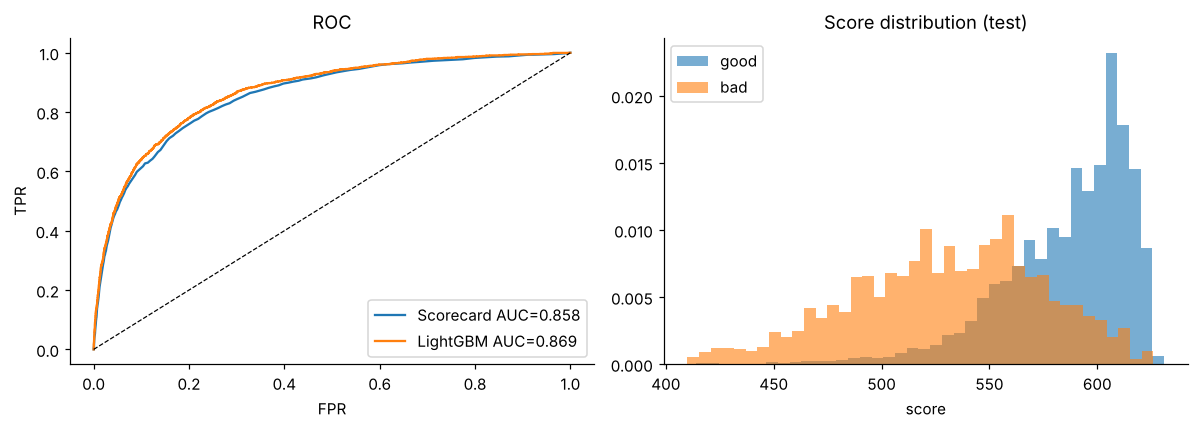

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, p in [("Scorecard", p_sc), ("LightGBM", p_gb)]:
    fpr, tpr, _ = roc_curve(te.target, p); ax[0].plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(te.target, p):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC"); ax[0].legend()
ax[1].hist(s_te[te.target.values == 0], bins=40, alpha=.6, density=True, label="good")
ax[1].hist(s_te[te.target.values == 1], bins=40, alpha=.6, density=True, label="bad")
ax[1].set(title="Score distribution (test)", xlabel="score"); ax[1].legend()
plt.tight_layout(); plt.savefig(ROOT / "reports/roc_score_dist.png", bbox_inches="tight"); plt.show()

## 7. 비즈니스 분석: 승인 기준점(cut-off)을 어디에 둘까

GMSC에는 대출금액이 없으므로 **1건당 동일 금액**을 가정하고 손익 구조를 단순화한다.
- 정상 고객 1명 승인 → **+1** (순이자수익, 원금의 약 10%)
- 부도 고객 1명 승인 → **−6** (손실률 LGD 60% 가정 → 이익의 6배)
- 거절 → 0

이 가정 비율(손실/이익)이 바뀌면 최적점도 바뀌므로, 뒤에서 민감도 분석을 한다.

In [12]:
GAIN, LOSS = 1.0, 6.0

def cutoff_table(score, y, cuts):
    score, y = np.asarray(score), np.asarray(y); rows = []
    n, nb = len(y), y.sum()
    for c in cuts:
        a = score >= c
        good, bad = ((y == 0) & a).sum(), ((y == 1) & a).sum()
        rows.append({"cutoff": c, "승인율": a.mean(), "승인자 부도율": bad / max(a.sum(), 1),
                     "부도 차단율": 1 - bad / nb, "정상 거절율": 1 - good / (n - nb),
                     "손익(1인당)": (GAIN * good - LOSS * bad) / n})
    return pd.DataFrame(rows)

# cut-off는 검증셋에서 정하고, 성과는 한 번도 안 본 테스트셋에서 측정한다 (테스트셋 과적합 방지)
s_va = sc.score_frame(card, va)
cuts = np.arange(440, 621, 5)
ct = cutoff_table(s_te, te.target, cuts)
ct.to_csv(ROOT / "reports/cutoff_table.csv", index=False, encoding="utf-8-sig")
baseline_profit = (GAIN * (te.target == 0).sum() - LOSS * te.target.sum()) / len(te)
print(f"전원 승인 시 손익(1인당): {baseline_profit:.4f}  (부도율 {te.target.mean():.2%})")
ct.iloc[::3]

전원 승인 시 손익(1인당): 0.5322  (부도율 6.68%)


,cutoff,승인율,승인자 부도율,부도 차단율,정상 거절율,손익(1인당)
0,440,0.9970,0.0650,0.0304,0.0011,0.5434
3,455,0.9938,0.0636,0.0539,0.0028,0.5511
6,470,0.9886,0.0609,0.0993,0.0051,0.5672
9,485,0.9814,0.0575,0.1561,0.0088,0.5866
12,500,0.9681,0.0517,0.2514,0.0162,0.6178
15,515,0.9509,0.0457,0.3501,0.0275,0.6469
18,530,0.9227,0.0383,0.4713,0.0491,0.6753
21,545,0.8796,0.0313,0.5880,0.0869,0.6869
24,560,0.7911,0.0230,0.7282,0.1717,0.6639
27,575,0.6699,0.0161,0.8384,0.2937,0.5943


In [13]:
# ① 승인율 80% 시나리오
c80 = np.quantile(s_va, 0.20)              # 검증셋 기준 하위 20% 거절
a80 = s_te >= c80
br80 = te.target.values[a80].mean()
blocked80 = 1 - te.target.values[a80].sum() / te.target.sum()
profit80 = (GAIN * ((te.target.values == 0) & a80).sum() - LOSS * ((te.target.values == 1) & a80).sum()) / len(te)

# ② 손익 최대 cut-off
grid = np.arange(400, 640, 1)
best_cut = grid[cutoff_table(s_va, va.target, grid)["손익(1인당)"].values.argmax()]   # 검증셋에서 선택
fine = cutoff_table(s_te, te.target, grid)                                          # 테스트셋 성과
best = fine.set_index("cutoff").loc[best_cut]; best["cutoff"] = best_cut

res = pd.DataFrame({
    "전원 승인": [1.0, te.target.mean(), 0.0, baseline_profit],
    f"승인율 80% (cut-off {c80:.0f}점)": [a80.mean(), br80, blocked80, profit80],
    f"손익 최대 (cut-off {best.cutoff:.0f}점)": [best["승인율"], best["승인자 부도율"], best["부도 차단율"], best["손익(1인당)"]],
}, index=["승인율", "승인자 부도율", "부도 차단율", "손익(1인당)"]).T
res

,승인율,승인자 부도율,부도 차단율,손익(1인당)
전원 승인,1.0000,0.0668,0.0000,0.5322
승인율 80% (cut-off 558점),0.8041,0.0239,0.7122,0.6695
손익 최대 (cut-off 539점),0.8988,0.0338,0.5456,0.6862


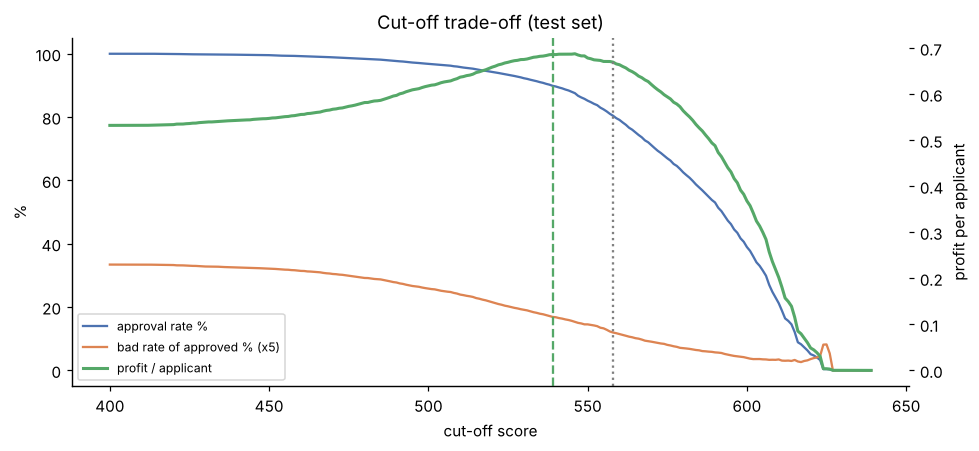

In [14]:
fig, ax1 = plt.subplots(figsize=(9, 4.2))
ax1.plot(fine.cutoff, fine["승인율"] * 100, label="approval rate %", c="#4C72B0")
ax1.plot(fine.cutoff, fine["승인자 부도율"] * 100 * 5, label="bad rate of approved % (x5)", c="#DD8452")
ax1.set_xlabel("cut-off score"); ax1.set_ylabel("%")
ax2 = ax1.twinx(); ax2.plot(fine.cutoff, fine["손익(1인당)"], c="#55A868", lw=2, label="profit / applicant")
ax2.axvline(best.cutoff, ls="--", c="#55A868"); ax2.axvline(c80, ls=":", c="gray")
ax2.set_ylabel("profit per applicant")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=8); ax1.set_title("Cut-off trade-off (test set)")
plt.tight_layout(); plt.savefig(ROOT / "reports/cutoff_tradeoff.png", bbox_inches="tight"); plt.show()

### 민감도: 손실/이익 비율 가정이 바뀌면?

In [15]:
sens = []
prof = lambda s, y, c, r: (((y == 0) & (s >= c)).sum() - r * ((y == 1) & (s >= c)).sum()) / len(y)
for ratio in [3, 4, 6, 8, 10, 15]:
    c = grid[int(np.argmax([prof(s_va, va.target.values, c, ratio) for c in grid]))]
    sens.append({"손실/이익 비율": ratio, "최적 cut-off(검증셋)": c,
                 "테스트 승인율": (s_te >= c).mean(), "테스트 1인당 손익": prof(s_te, te.target.values, c, ratio)})
sens = pd.DataFrame(sens); sens

,손실/이익 비율,최적 cut-off(검증셋),테스트 승인율,테스트 1인당 손익
0,3,524,0.9354,0.7824
1,4,536,0.9081,0.7471
2,6,539,0.8988,0.6862
3,8,546,0.8756,0.6341
4,10,556,0.8178,0.5871
5,15,572,0.6936,0.5016


### 블랙박스(LightGBM)는 그만한 가치가 있나?
같은 **승인율 80%** 조건에서 두 모델이 걸러내는 부도자 수를 비교한다.

In [16]:
def at_approval(p_bad, y, rate=0.8):
    a = p_bad <= np.quantile(p_bad, rate); y = np.asarray(y)
    good, bad = ((y == 0) & a).sum(), ((y == 1) & a).sum()
    return {"승인자 부도율": bad / a.sum(), "승인된 부도자 수": int(bad), "손익(1인당)": (GAIN * good - LOSS * bad) / len(y)}
cmp = pd.DataFrame({"스코어카드": at_approval(p_sc, te.target), "LightGBM": at_approval(p_gb, te.target)}).T
cmp.loc["차이(LGBM−SC)"] = cmp.loc["LightGBM"] - cmp.loc["스코어카드"]
print(f"테스트셋 {len(te):,}명 기준")
cmp

테스트셋 30,000명 기준


,승인자 부도율,승인된 부도자 수,손익(1인당)
스코어카드,0.0239,577.0000,0.6695
LightGBM,0.0224,537.0000,0.6747
차이(LGBM−SC),-0.0015,-40.0000,0.0052


## 8. 결론

In [17]:
summary = {
    "scorecard_auc": float(perf.loc["스코어카드", "AUC"]), "lgbm_auc": float(perf.loc["LightGBM", "AUC"]),
    "scorecard_ks": float(perf.loc["스코어카드", "KS"]), "psi": float(perf.loc["스코어카드", "PSI(train→test)"]),
    "baseline_bad_rate": float(te.target.mean()),
    "cut80": float(c80), "bad_rate80": float(br80), "blocked80": float(blocked80),
    "profit_all": float(baseline_profit), "profit80": float(profit80),
    "best_cut": float(best.cutoff), "best_approval": float(best["승인율"]), "best_profit": float(best["손익(1인당)"]),
    "n_test": int(len(te)), "lgbm_minus_sc_bads": int(cmp.loc["차이(LGBM−SC)", "승인된 부도자 수"]),
}
sc.save_json(summary, ROOT / "reports/summary.json"); summary

{'scorecard_auc': 0.8577454470628219,
 'lgbm_auc': 0.8690888780905389,
 'scorecard_ks': 0.5602132372230703,
 'psi': 0.00029788593604649656,
 'baseline_bad_rate': 0.06683333333333333,
 'cut80': 558.0,
 'bad_rate80': 0.023918089869010114,
 'blocked80': 0.712219451371571,
 'profit_all': 0.5321666666666667,
 'profit80': 0.6695,
 'best_cut': 539.0,
 'best_approval': 0.8987666666666667,
 'best_profit': 0.6862,
 'n_test': 30000,
 'lgbm_minus_sc_bads': -40}

**핵심 결과 (테스트셋 30,000명, cut-off는 검증셋에서 결정)**

1. **스코어카드 성능**: AUC 0.858, KS 0.56, PSI 0.0003. 9개 변수만 쓰고 구간별 점수표로 모든 판단을 설명할 수 있다.
2. **승인율 80% 운영 시** (558점 이상 승인): 승인자 부도율이 6.7%에서 **2.4%**로 떨어진다. 부도자의 **71%를 사전에 차단**하고, 정상 고객 거절은 약 16%에 그친다. 1인당 손익은 전원 승인 대비 **+26%**.
3. **그런데 80%가 최선은 아니다.** 손실/이익 비율 6배 가정에서 손익이 최대인 기준점은 **539점(승인율 약 90%)**이고, 손익은 전원 승인 대비 **+29%**다. 80% 목표를 고집하면 손익을 약 2.4% 포기하게 된다. 80%가 최적이 되려면 부도 1건 손실이 정상 1건 이익의 **약 10배**여야 한다. 즉 **승인율 목표는 감이 아니라 손실 구조(LGD, 마진)에 맞춰 정해야 한다.**
4. **LightGBM vs 스코어카드**: AUC는 +0.011 높다. 하지만 같은 승인율 80%에서 막는 부도는 3만 명당 40건(약 7%) 더 많을 뿐이고, 손익 차이는 +0.8%다. 금융권은 거절 사유 설명 의무와 감독 대응이 필요하다. 이를 고려하면 **현 단계에서는 스코어카드를 운영 모델로, LightGBM은 챌린저 모델로 모니터링**하는 구성을 권한다.

**한계와 다음 단계**
- 대출금액과 금리가 없어 손익을 1건당 동일 금액으로 가정했다. Lending Club 데이터(금액·금리 포함)로 실제 금액 기반 손익을 재검증할 예정이다.
- 거절된 사람의 실제 결과는 알 수 없다(Reject Inference 미적용).
- 랜덤 분할이므로 시간 흐름에 따른 안정성(Out-of-Time)은 별도 검증이 필요하다.